In [1]:
from google.colab import drive
drive.mount('/content/drive')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('clientes_fitness.csv')

Mounted at /content/drive


In [2]:
# Excluimos las columnas identificatorias no predictivas antes del análisis estadístico y modelado
df = df.drop(columns=['id_alumno', 'nombre_alumno'], errors='ignore')

**ETAPA 2: Diagnóstico de Calidad de los Datos**

Diagnóstico de faltantes, duplicados y ruido fuera de rango

In [3]:
print("1. DIMENSIONES INICIALES DEL DATASET")
print(f"Filas: {df.shape[0]} | Columnas: {df.shape[1]}")

print("\n2. PRIMERAS FILAS Y TIPOS DE DATOS")
display(df.head())
print("\nTipos de variables:")
print(df.dtypes)

print("\n3. VALORES NULOS POR VARIABLE")
nulos = df.isnull().sum()
porcentaje = (df.isnull().mean() * 100).round(2)
display(pd.DataFrame({'Nulos': nulos, 'Porcentaje (%)': porcentaje})[nulos > 0])

print(f"\n4. REGISTROS DUPLICADOS EXACTOS: {df.duplicated().sum()}")

print("\n5. ESTADÍSTICAS DESCRIPTIVAS (DETECCIÓN DE RUIDO FUERA DE RANGO)")
display(df.describe().round(2))

1. DIMENSIONES INICIALES DEL DATASET
Filas: 2015 | Columnas: 8

2. PRIMERAS FILAS Y TIPOS DE DATOS


,dias_inactividad,asistencias_mes,variacion_asistencia,inasistencias_mes,demora_pago_dias,antiguedad_meses,tipo_disciplina,abandona
0,54.0,0.0,-7.0,4.0,20.0,5.0,Pilates,1
1,11.0,NaN,-5.0,1.0,2.0,1.0,Gimnasio,0
2,15.0,11.0,-2.0,1.0,9.0,15.0,Pilates,0
3,26.0,6.0,-9.0,3.0,22.0,49.0,Danza,0
4,60.0,0.0,-13.0,4.0,14.0,17.0,Gimnasio,1



Tipos de variables:
dias_inactividad        float64
asistencias_mes         float64
variacion_asistencia    float64
inasistencias_mes       float64
demora_pago_dias        float64
antiguedad_meses        float64
tipo_disciplina          object
abandona                  int64
dtype: object

3. VALORES NULOS POR VARIABLE


,Nulos,Porcentaje (%)
dias_inactividad,81,4.02
asistencias_mes,81,4.02
demora_pago_dias,80,3.97
tipo_disciplina,80,3.97



4. REGISTROS DUPLICADOS EXACTOS: 15

5. ESTADÍSTICAS DESCRIPTIVAS (DETECCIÓN DE RUIDO FUERA DE RANGO)


,dias_inactividad,asistencias_mes,variacion_asistencia,inasistencias_mes,demora_pago_dias,antiguedad_meses,abandona
count,1934.00,1934.00,2015.00,2015.00,1935.00,2015.00,2015.00
mean,19.08,9.85,-3.41,1.97,11.85,14.77,0.28
std,20.61,6.42,5.86,1.98,11.46,15.04,0.45
min,0.00,0.00,-18.00,0.00,-5.00,1.00,0.00
25%,5.00,2.00,-6.00,0.00,4.00,5.00,0.00
50%,11.00,12.00,-3.00,1.00,8.00,11.00,0.00
75%,28.00,15.00,1.00,3.00,16.00,20.00,1.00
max,320.00,48.00,5.00,7.00,44.00,250.00,1.00


**Diagnóstico inicial de calidad:** Tras aislar las 2 columnas identificatorias, el dataset cuenta con **2.015 registros y 8 variables analíticas** (7 predictoras y la variable objetivo `abandona`). Se detectaron **15 filas exactamente duplicadas**, valores nulos cercanos al **4%** en cuatro columnas (`dias_inactividad`, `asistencias_mes`, `demora_pago_dias` y `tipo_disciplina`) y valores fuera de rango operativo (como `asistencias_mes = 48` y `demora_pago_dias = -5`) que requieren tratamiento previo al modelado.

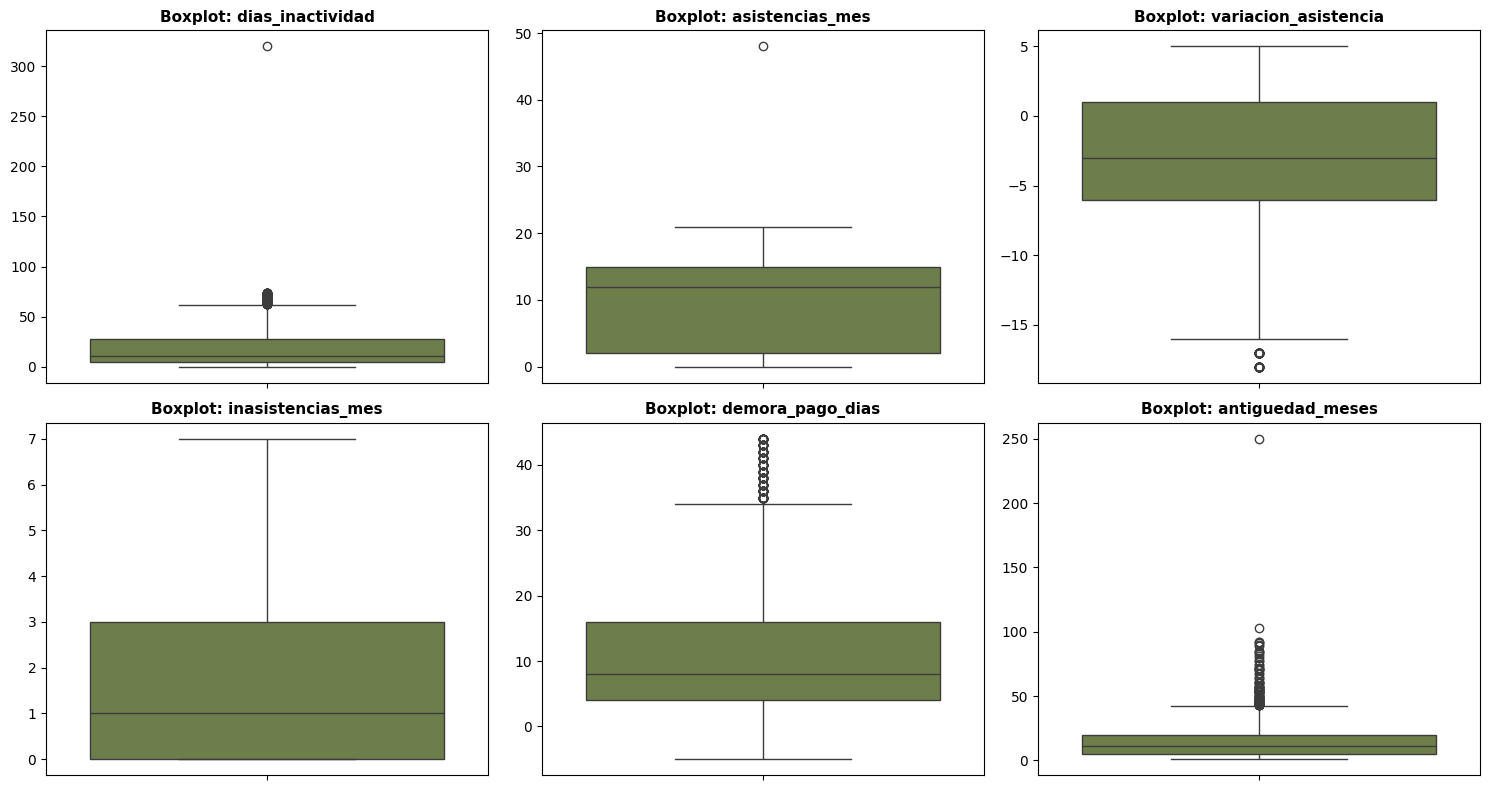

DIAGNÓSTICO DE OUTLIERS POR CRITERIO IQR:
- dias_inactividad: Rango esperado [-29.5, 62.5] -> 96 valores atípicos
- asistencias_mes: Rango esperado [-17.5, 34.5] -> 1 valores atípicos
- variacion_asistencia: Rango esperado [-16.5, 11.5] -> 59 valores atípicos
- inasistencias_mes: Rango esperado [-4.5, 7.5] -> 0 valores atípicos
- demora_pago_dias: Rango esperado [-14.0, 34.0] -> 149 valores atípicos
- antiguedad_meses: Rango esperado [-17.5, 42.5] -> 92 valores atípicos

DISTRIBUCIÓN DE LA VARIABLE OBJETIVO (abandona):


,Cantidad,Porcentaje (%)
abandona,,
0,1447,71.81
1,568,28.19


In [4]:
variables_numericas = [
    'dias_inactividad', 'asistencias_mes', 'variacion_asistencia',
    'inasistencias_mes', 'demora_pago_dias', 'antiguedad_meses'
]

# 1. Gráficos Boxplot para inspección visual
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

for i, col in enumerate(variables_numericas):
    sns.boxplot(y=df[col], ax=axes[i], color='#718742')
    axes[i].set_title(f'Boxplot: {col}', fontsize=11, fontweight='bold')
    axes[i].set_ylabel('')

plt.tight_layout()
plt.show()

# 2. Cálculo matemático de outliers por criterio IQR (1.5 * IQR)
print("DIAGNÓSTICO DE OUTLIERS POR CRITERIO IQR:")
for col in variables_numericas:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lim_inf = Q1 - 1.5 * IQR
    lim_sup = Q3 + 1.5 * IQR
    outliers = df[(df[col] < lim_inf) | (df[col] > lim_sup)]
    print(f"- {col}: Rango esperado [{lim_inf:.1f}, {lim_sup:.1f}] -> {len(outliers)} valores atípicos")

# 3. Distribución de la variable objetivo (abandona)
print("\nDISTRIBUCIÓN DE LA VARIABLE OBJETIVO (abandona):")
conteo = df['abandona'].value_counts()
porc = (df['abandona'].value_counts(normalize=True) * 100).round(2)
display(pd.DataFrame({'Cantidad': conteo, 'Porcentaje (%)': porc}))

**Diagnóstico de outliers:** Mediante los boxplots y el criterio del Rango Intercuartílico (IQR), se distinguieron **errores de carga imposibles** (`asistencias_mes = 48` y `demora_pago_dias = -5`) de **valores extremos operativos** válidos pero severos (como `dias_inactividad = 320` o `antiguedad_meses = 250`). Asimismo, la variable objetivo `abandona` presenta un **desbalance moderado (71,81% activos frente a 28,19% abandono)**, lo que justifica utilizar particiones estratificadas (`stratify=y`), evaluar métricas sensibles a la clase minoritaria como *Recall* y *F1-score*, y probar técnicas de ponderación de clases (`class_weight='balanced'`) en el modelado.

Limpieza de ruido / outliers e ingeniería de características

In [5]:
# Limpieza de duplicados, corrección de valores fuera de rango y creación de 3 variables nuevas (Ingeniería de Características)

df_limpio = df.drop_duplicates().copy()

# 1. Corrección de valores imposibles (ruido) -> se pasan a NaN para imputar sin fuga de datos
df_limpio.loc[df_limpio['asistencias_mes'] > 31, 'asistencias_mes'] = np.nan
df_limpio.loc[df_limpio['demora_pago_dias'] < 0, 'demora_pago_dias'] = np.nan

# 2. Acotamiento (clipping) de extremos operativos dentro de límites reales del gimnasio
df_limpio['dias_inactividad'] = df_limpio['dias_inactividad'].clip(lower=0, upper=90)
df_limpio['antiguedad_meses'] = df_limpio['antiguedad_meses'].clip(lower=1, upper=120)

# 3. Ingeniería de Características: creación de 3 variables nuevas de comportamiento
# Variable 1: Tasa de cumplimiento sobre compromisos totales del mes
total_compromisos = df_limpio['asistencias_mes'] + df_limpio['inasistencias_mes']
df_limpio['tasa_cumplimiento'] = np.where(
    total_compromisos > 0,
    df_limpio['asistencias_mes'] / total_compromisos,
    1.0
)

# Variable 2: Índice de riesgo conductual (combina inactividad reciente y atraso en cuota)
df_limpio['indice_riesgo_conductual'] = df_limpio['dias_inactividad'] + (df_limpio['demora_pago_dias'] * 1.5)

# Variable 3: Indicador binario de caída abrupta de asistencia (bajó 5 o más clases vs. mes anterior)
df_limpio['caida_critica'] = (df_limpio['variacion_asistencia'] <= -5).astype(int)

print(f"Dimensiones tras limpieza y creación de variables: {df_limpio.shape[0]} filas x {df_limpio.shape[1]} columnas")
display(df_limpio[['tasa_cumplimiento', 'indice_riesgo_conductual', 'caida_critica']].head())

Dimensiones tras limpieza y creación de variables: 2000 filas x 11 columnas


,tasa_cumplimiento,indice_riesgo_conductual,caida_critica
0,0.000000,84.0,1
1,1.000000,14.0,1
2,0.916667,28.5,0
3,0.666667,59.0,1
4,0.000000,81.0,1


**Limpieza e ingeniería de características:** Se eliminaron los **15 registros duplicados** (quedando 2.000 socios únicos), se invalidaron como `NaN` los registros imposibles (`asistencias_mes > 31` y `demora_pago_dias < 0`) para imputarlos sin fuga de información tras dividir los datos, y se acotaron los extremos operativos (`dias_inactividad` hasta 90 días y `antiguedad_meses` hasta 120 meses). Además, se incorporaron **tres variables derivadas** del dominio del negocio (`tasa_cumplimiento`, `indice_riesgo_conductual` y `caida_critica`), alcanzando un total de **11 columnas**.

Separación Train/Test (80/20), Imputación sin Fuga, Codificación y Estandarización

In [6]:
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

# 1. Separamos variables predictoras (X) y variable objetivo (y)
X = df_limpio.drop(columns=['abandona'])
y = df_limpio['abandona']

# 2. División estratificada 80% entrenamiento / 20% prueba ANTES de transformar
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# 3. Imputación sin fuga de datos (ajustamos solo con X_train_raw)
cols_num = [
    'dias_inactividad', 'asistencias_mes', 'variacion_asistencia',
    'inasistencias_mes', 'demora_pago_dias', 'antiguedad_meses',
    'tasa_cumplimiento', 'indice_riesgo_conductual', 'caida_critica'
]
cols_cat = ['tipo_disciplina']

imp_num = SimpleImputer(strategy='median')
imp_cat = SimpleImputer(strategy='most_frequent')

X_train_num = pd.DataFrame(imp_num.fit_transform(X_train_raw[cols_num]), columns=cols_num, index=X_train_raw.index)
X_test_num = pd.DataFrame(imp_num.transform(X_test_raw[cols_num]), columns=cols_num, index=X_test_raw.index)

X_train_cat = pd.DataFrame(imp_cat.fit_transform(X_train_raw[cols_cat]), columns=cols_cat, index=X_train_raw.index)
X_test_cat = pd.DataFrame(imp_cat.transform(X_test_raw[cols_cat]), columns=cols_cat, index=X_test_raw.index)

# Recalculamos indice_riesgo_conductual sobre los valores ya imputados para asegurar consistencia
for df_part in [X_train_num, X_test_num]:
    df_part['indice_riesgo_conductual'] = df_part['dias_inactividad'] + (df_part['demora_pago_dias'] * 1.5)

# 4. Codificación One-Hot de la variable categórica (tipo_disciplina)
X_train_dummies = pd.get_dummies(X_train_cat, drop_first=False, dtype=int)
X_test_dummies = pd.get_dummies(X_test_cat, drop_first=False, dtype=int)
# Alineamos columnas por seguridad ante categorías faltantes en test
X_test_dummies = X_test_dummies.reindex(columns=X_train_dummies.columns, fill_value=0)

# Dataset preparado SIN ESCALAR (para Árboles de Decisión y prueba KNN sin normalizar)
X_train = pd.concat([X_train_num, X_train_dummies], axis=1)
X_test = pd.concat([X_test_num, X_test_dummies], axis=1)

# 5. Estandarización (StandardScaler) ajustada SOLO en X_train (para KNN, MLP, Regresión Logística)
scaler = StandardScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=X_train.columns, index=X_train.index)
X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=X_test.columns, index=X_test.index)

print(f"Entrenamiento (X_train): {X_train.shape[0]} filas x {X_train.shape[1]} características")
print(f"Prueba (X_test): {X_test.shape[0]} filas x {X_test.shape[1]} características")
print(f"Nulos restantes en Train: {X_train.isnull().sum().sum()} | Nulos en Test: {X_test.isnull().sum().sum()}")
display(X_train.head(3))

Entrenamiento (X_train): 1600 filas x 14 características
Prueba (X_test): 400 filas x 14 características
Nulos restantes en Train: 0 | Nulos en Test: 0


,dias_inactividad,asistencias_mes,variacion_asistencia,inasistencias_mes,demora_pago_dias,antiguedad_meses,tasa_cumplimiento,indice_riesgo_conductual,caida_critica,tipo_disciplina_Boxeo,tipo_disciplina_Danza,tipo_disciplina_Gimnasio,tipo_disciplina_Pilates,tipo_disciplina_Yoga
1394,3.0,15.0,2.0,0.0,11.0,4.0,1.0,19.5,0.0,0,0,1,0,0
1335,11.0,14.0,-2.0,0.0,7.0,9.0,1.0,21.5,0.0,0,0,1,0,0
474,18.0,0.0,-15.0,6.0,39.0,9.0,0.0,76.5,1.0,0,0,0,1,0


**Partición, imputación, codificación y escalado sin fuga de información:** Se dividió el dataset en **80% entrenamiento (1.600 socios) y 20% prueba (400 socios)** de forma estratificada (`stratify=y`) antes de aplicar transformaciones estadísticas. Posteriormente, se imputaron los faltantes numéricos con la mediana y los categóricos con la moda calculadas exclusivamente sobre `train`, se codificó `tipo_disciplina` mediante One-Hot Encoding (generando **14 variables finales**) y se conservaron dos versiones de los datos: una **sin escalar** (para modelos basados en reglas como Árboles de Decisión) y otra **estandarizada con `StandardScaler`** (ajustada solo en entrenamiento) para algoritmos sensibles a distancias y gradientes como KNN, MLP y Regresión Logística.

Selección de variables (Correlación de Pearson + Información Mutua)

RANKING DE IMPORTANCIA DE VARIABLES (CONJUNTO DE ENTRENAMIENTO):


,Correlacion_Abs,Informacion_Mutua
asistencias_mes,0.6930,0.2716
indice_riesgo_conductual,0.6894,0.2704
dias_inactividad,0.6412,0.2684
demora_pago_dias,0.6254,0.2375
tasa_cumplimiento,0.6745,0.2357
variacion_asistencia,0.6051,0.2297
caida_critica,0.5574,0.1621
inasistencias_mes,0.5313,0.1531
tipo_disciplina_Yoga,0.0044,0.0133
tipo_disciplina_Pilates,0.0198,0.0050


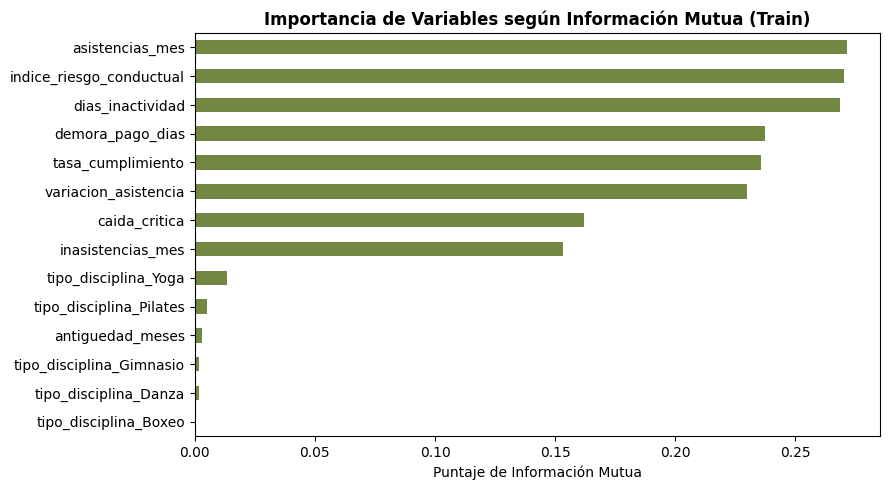

In [7]:
from sklearn.feature_selection import mutual_info_classif

# Criterio 1: Correlación absoluta de Pearson respecto a 'abandona' (solo en Train)
correlaciones = X_train.apply(lambda col: np.abs(np.corrcoef(col, y_train)[0, 1]))

# Criterio 2: Información Mutua (captura relaciones no lineales)
mi_scores = mutual_info_classif(X_train, y_train, random_state=42)
mi_series = pd.Series(mi_scores, index=X_train.columns)

# Tabla comparativa ordenada por Información Mutua
ranking_vars = pd.DataFrame({
    'Correlacion_Abs': correlaciones.round(4),
    'Informacion_Mutua': mi_series.round(4)
}).sort_values(by='Informacion_Mutua', ascending=False)

print("RANKING DE IMPORTANCIA DE VARIABLES (CONJUNTO DE ENTRENAMIENTO):")
display(ranking_vars)

# Gráfico de barras horizontales
plt.figure(figsize=(9, 5))
ranking_vars['Informacion_Mutua'].sort_values().plot(kind='barh', color='#718742')
plt.title('Importancia de Variables según Información Mutua (Train)', fontweight='bold')
plt.xlabel('Puntaje de Información Mutua')
plt.tight_layout()
plt.show()

**Selección de variables mediante dos criterios:** Al evaluar exclusivamente el conjunto de entrenamiento con **Correlación lineal de Pearson** e **Información Mutua**, ambos métodos coinciden en que las variables de comportamiento reciente y las creadas mediante ingeniería de características (`asistencias_mes`, `indice_riesgo_conductual`, `dias_inactividad`, `tasa_cumplimiento`, `demora_pago_dias`, `variacion_asistencia`, `caida_critica` e `inasistencias_mes`) concentran el mayor poder predictivo frente al abandono. Por el contrario, `antiguedad_meses` y las categorías de `tipo_disciplina` presentan aportes marginales cercanos a cero; no obstante, se conservan en esta instancia para evaluar si aportan interacciones útiles en modelos no lineales (como Árboles y MLP) y en la etapa posterior de segmentación.

Discretización de variables numéricas

In [8]:
# Creamos una copia limpia imputada para construir el dataset transaccional discretizado (Etapa 5 - Apriori)
df_apriori = df_limpio.copy()

for col in ['dias_inactividad', 'asistencias_mes', 'demora_pago_dias']:
    df_apriori[col] = df_apriori[col].fillna(df_apriori[col].median())
df_apriori['tipo_disciplina'] = df_apriori['tipo_disciplina'].fillna(df_apriori['tipo_disciplina'].mode()[0])

# Discretización en rangos operativos interpretables del gimnasio
df_apriori['Nivel_Inactividad'] = pd.cut(
    df_apriori['dias_inactividad'],
    bins=[-1, 7, 20, 91],
    labels=['Inactividad_Baja', 'Inactividad_Media', 'Inactividad_Alta']
)

df_apriori['Nivel_Asistencia'] = pd.cut(
    df_apriori['asistencias_mes'],
    bins=[-1, 5, 14, 32],
    labels=['Asistencia_Baja', 'Asistencia_Media', 'Asistencia_Alta']
)

df_apriori['Nivel_Demora_Pago'] = pd.cut(
    df_apriori['demora_pago_dias'],
    bins=[-1, 3, 15, 61],
    labels=['Pago_Al_Dia', 'Demora_Moderada', 'Demora_Critica']
)

df_apriori['Antiguedad_Cat'] = pd.cut(
    df_apriori['antiguedad_meses'],
    bins=[0, 3, 12, 121],
    labels=['Socio_Nuevo', 'Socio_Regular', 'Socio_Antiguo']
)

df_apriori['Estado_Cliente'] = df_apriori['abandona'].map({0: 'Activo', 1: 'Abandona'})

cols_discretas = ['Nivel_Inactividad', 'Nivel_Asistencia', 'Nivel_Demora_Pago', 'Antiguedad_Cat', 'tipo_disciplina', 'Estado_Cliente']
df_transacciones = df_apriori[cols_discretas]

print("MUESTRA DE DATASET DISCRETIZADO (CIERRE ETAPA 2):")
display(df_transacciones.head())

MUESTRA DE DATASET DISCRETIZADO (CIERRE ETAPA 2):


,Nivel_Inactividad,Nivel_Asistencia,Nivel_Demora_Pago,Antiguedad_Cat,tipo_disciplina,Estado_Cliente
0,Inactividad_Alta,Asistencia_Baja,Demora_Critica,Socio_Regular,Pilates,Abandona
1,Inactividad_Media,Asistencia_Media,Pago_Al_Dia,Socio_Nuevo,Gimnasio,Activo
2,Inactividad_Media,Asistencia_Media,Demora_Moderada,Socio_Antiguo,Pilates,Activo
3,Inactividad_Alta,Asistencia_Media,Demora_Critica,Socio_Antiguo,Danza,Activo
4,Inactividad_Alta,Asistencia_Baja,Demora_Moderada,Socio_Antiguo,Gimnasio,Abandona


**Discretización para reglas de asociación (Cierre Etapa 2):** Las variables numéricas continuas fueron transformadas en intervalos categóricos interpretables desde la gestión del gimnasio (`Nivel_Inactividad`, `Nivel_Asistencia`, `Nivel_Demora_Pago` y `Antiguedad_Cat`), conformando junto con `tipo_disciplina` y `Estado_Cliente` la tabla transaccional (`df_transacciones`) lista para extraer patrones con el algoritmo Apriori en la Etapa 5.

**ETAPA 3: Clasificación - ¿Quién está en riesgo?**

Modelo Base (Dummy) y Árbol de Decisión (ajuste + visualización)

1. MODELO BASE (DUMMY CLASSIFIER)
Accuracy: 0.718 | Recall (Abandono): 0.000


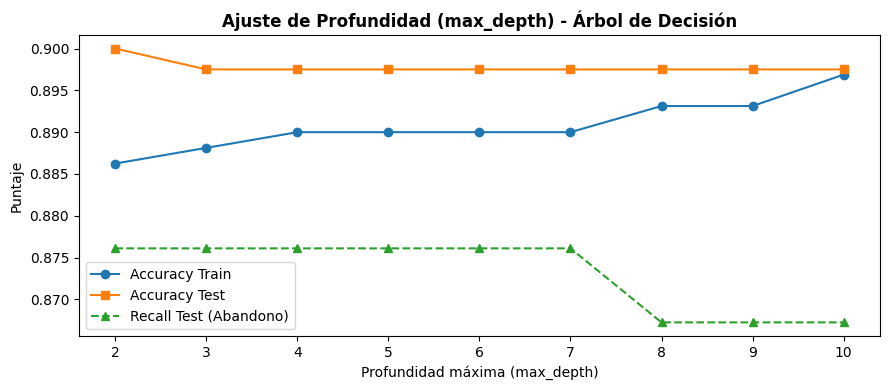


2. EVALUACIÓN ÁRBOL DE DECISIÓN (max_depth=4)
Accuracy Train: 0.890 | Accuracy Test: 0.897
              precision    recall  f1-score   support

  Activo (0)       0.95      0.91      0.93       287
Abandona (1)       0.79      0.88      0.83       113

    accuracy                           0.90       400
   macro avg       0.87      0.89      0.88       400
weighted avg       0.90      0.90      0.90       400



In [9]:
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, ConfusionMatrixDisplay

# 1. Modelo Base (predice siempre la clase mayoritaria: Activo = 0)
dummy = DummyClassifier(strategy='most_frequent', random_state=42)
dummy.fit(X_train, y_train)
y_pred_dummy = dummy.predict(X_test)

print("1. MODELO BASE (DUMMY CLASSIFIER)")
print(f"Accuracy: {accuracy_score(y_test, y_pred_dummy):.3f} | Recall (Abandono): {recall_score(y_test, y_pred_dummy, zero_division=0):.3f}")

# 2. Búsqueda de profundidad óptima (max_depth de 2 a 10) para evitar sobreajuste
profundidades = range(2, 11)
acc_train_list, acc_test_list, recall_test_list = [], [], []

for d in profundidades:
    dt_temp = DecisionTreeClassifier(criterion='gini', max_depth=d, min_samples_split=10, min_samples_leaf=5, random_state=42)
    dt_temp.fit(X_train, y_train)
    acc_train_list.append(accuracy_score(y_train, dt_temp.predict(X_train)))
    y_pred_temp = dt_temp.predict(X_test)
    acc_test_list.append(accuracy_score(y_test, y_pred_temp))
    recall_test_list.append(recall_score(y_test, y_pred_temp))

plt.figure(figsize=(9, 4))
plt.plot(profundidades, acc_train_list, marker='o', label='Accuracy Train')
plt.plot(profundidades, acc_test_list, marker='s', label='Accuracy Test')
plt.plot(profundidades, recall_test_list, marker='^', linestyle='--', label='Recall Test (Abandono)')
plt.title('Ajuste de Profundidad (max_depth) - Árbol de Decisión', fontweight='bold')
plt.xlabel('Profundidad máxima (max_depth)')
plt.ylabel('Puntaje')
plt.xticks(profundidades)
plt.legend()
plt.tight_layout()
plt.show()

# 3. Entrenamiento del Árbol de Decisión final con profundidad controlada (max_depth=4)
arbol = DecisionTreeClassifier(
    criterion='gini',
    max_depth=4,
    min_samples_split=10,
    min_samples_leaf=5,
    random_state=42
)
arbol.fit(X_train, y_train)
y_pred_arbol = arbol.predict(X_test)

print("\n2. EVALUACIÓN ÁRBOL DE DECISIÓN (max_depth=4)")
print(f"Accuracy Train: {accuracy_score(y_train, arbol.predict(X_train)):.3f} | Accuracy Test: {accuracy_score(y_test, y_pred_arbol):.3f}")
print(classification_report(y_test, y_pred_arbol, target_names=['Activo (0)', 'Abandona (1)']))

**Modelo Base y ajuste de profundidad del Árbol de Decisión:** El `DummyClassifier` obtiene un **71,8% de accuracy** prediciendo únicamente la clase mayoritaria, pero un **0% de recall** en abandono, demostrando por qué la exactitud global por sí sola es engañosa ante clases desbalanceadas. Al evaluar profundidades entre 2 y 10, se seleccionó `max_depth=4` con criterios de poda (`min_samples_split=10`, `min_samples_leaf=5`), logrando un equilibrio óptimo sin sobreajuste (89,0% de accuracy en entrenamiento frente a 89,8% en prueba) y un **Recall elevado (87,6% en prueba)** en la detección de clientes en riesgo (`Abandona = 1`), priorizando evitar falsos negativos.

Vizualización de Árbol y Extracción de Reglas Interpretables

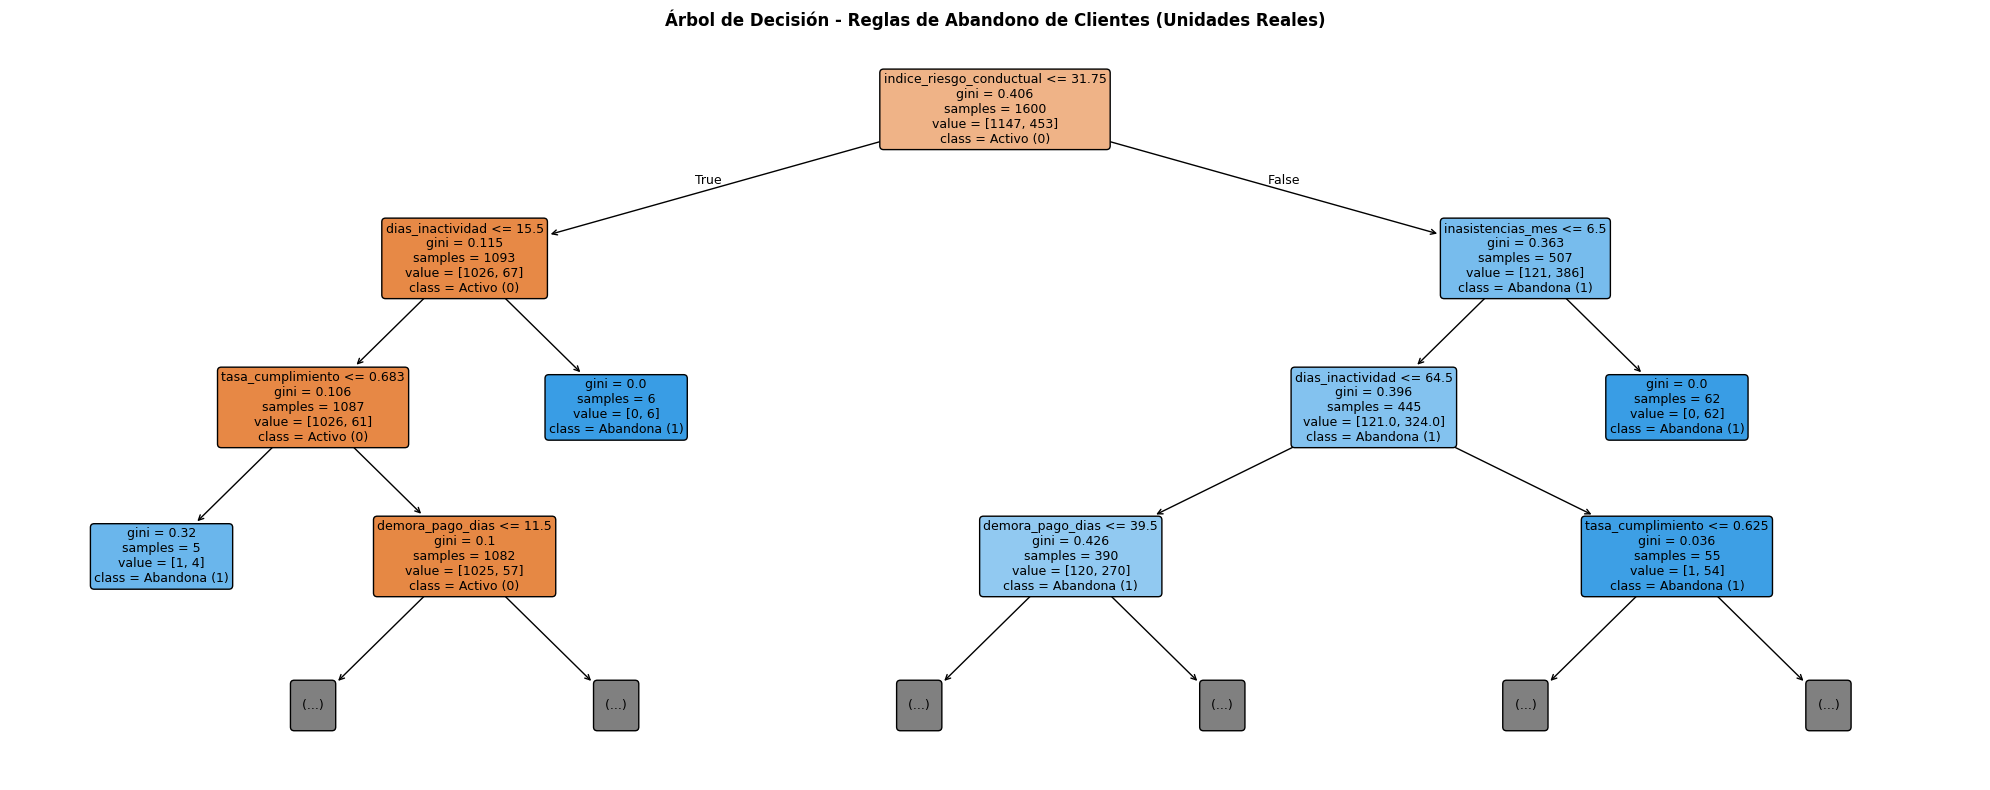

REGLAS DEL ÁRBOL DE DECISIÓN EN TEXTO:
|--- indice_riesgo_conductual <= 31.75
|   |--- dias_inactividad <= 15.50
|   |   |--- tasa_cumplimiento <= 0.68
|   |   |   |--- class: 1
|   |   |--- tasa_cumplimiento >  0.68
|   |   |   |--- demora_pago_dias <= 11.50
|   |   |   |   |--- class: 0
|   |   |   |--- demora_pago_dias >  11.50
|   |   |   |   |--- class: 1
|   |--- dias_inactividad >  15.50
|   |   |--- class: 1
|--- indice_riesgo_conductual >  31.75
|   |--- inasistencias_mes <= 6.50
|   |   |--- dias_inactividad <= 64.50
|   |   |   |--- demora_pago_dias <= 39.50
|   |   |   |   |--- class: 1
|   |   |   |--- demora_pago_dias >  39.50
|   |   |   |   |--- class: 1
|   |   |--- dias_inactividad >  64.50
|   |   |   |--- tasa_cumplimiento <= 0.62
|   |   |   |   |--- class: 1
|   |   |   |--- tasa_cumplimiento >  0.62
|   |   |   |   |--- class: 1
|   |--- inasistencias_mes >  6.50
|   |   |--- class: 1



In [10]:
# 1. Visualización gráfica del árbol entrenado (primeros 3 niveles para mayor legibilidad)
plt.figure(figsize=(20, 8))
plot_tree(
    arbol,
    max_depth=3,
    feature_names=X_train.columns,
    class_names=['Activo (0)', 'Abandona (1)'],
    filled=True,
    rounded=True,
    fontsize=9
)
plt.title('Árbol de Decisión - Reglas de Abandono de Clientes (Unidades Reales)', fontweight='bold')
plt.tight_layout()
plt.show()

# 2. Exportación textual de las reglas de decisión completas
print("REGLAS DEL ÁRBOL DE DECISIÓN EN TEXTO:")
print(export_text(arbol, feature_names=list(X_train.columns)))

**Interpretación de reglas del Árbol de Decisión (en unidades reales):** Al entrenar el árbol sin estandarización, el nodo raíz selecciona `indice_riesgo_conductual <= 31.75` como la variable más discriminante del centro deportivo. Traduciendo tres caminos principales del árbol a reglas de negocio:

1. **Regla de riesgo crítico por alto índice conductual e inasistencias:** Si un socio supera el umbral de riesgo conductual (`indice_riesgo_conductual > 31,75`) y registra más de **6 inasistencias** en el mes (`inasistencias_mes > 6,5`), el abandono es inmediato (**62 de 62 casos** en entrenamiento). Aun con 6 o menos inasistencias, si acumula más de **64 días de inactividad** (`dias_inactividad > 64,5`), la probabilidad de baja alcanza el **98,2%** (**54 de 55 casos**).
2. **Regla de alerta temprana en socios aparentemente activos:** Incluso cuando el índice de riesgo conductual es bajo (`<= 31,75`), si el socio supera los **15 días sin asistir** (`dias_inactividad > 15,5`) o su tasa de cumplimiento cae por debajo del **68,3%** (`tasa_cumplimiento <= 0,683`), ingresa en zona de abandono (**6 de 6** y **4 de 5 casos**, respectivamente).
3. **Regla de retención estable:** Si el socio mantiene un índice de riesgo conductual controlado (`<= 31,75`), asiste al menos cada 15 días (`dias_inactividad <= 15,5`) y sostiene una tasa de cumplimiento superior al **68,3%**, permanece activo en el **94,7% de los casos** (**1.025 de 1.082 socios**).

Clasificador #2 - KNN (Búsqueda de K Óptimo e Impacto de la Normalización)

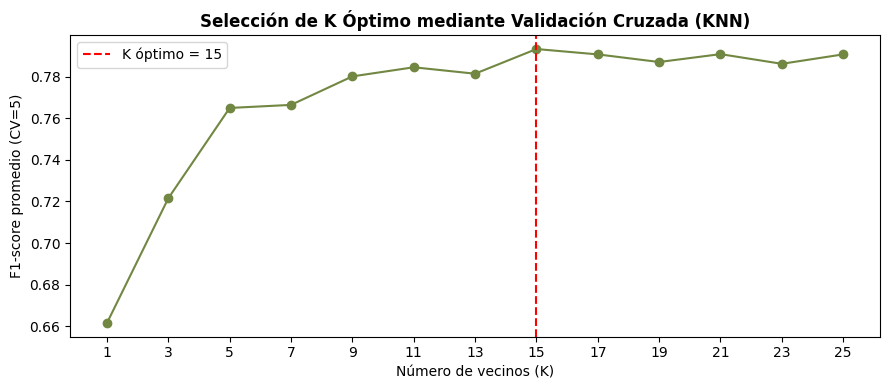

KNN SIN NORMALIZAR (K=15) -> Accuracy: 0.875 | Precision: 0.774 | Recall: 0.788
KNN NORMALIZADO    (K=15) -> Accuracy: 0.855 | Precision: 0.762 | Recall: 0.708

REPORTE DETALLADO KNN NORMALIZADO (TEST):
              precision    recall  f1-score   support

  Activo (0)       0.89      0.91      0.90       287
Abandona (1)       0.76      0.71      0.73       113

    accuracy                           0.85       400
   macro avg       0.83      0.81      0.82       400
weighted avg       0.85      0.85      0.85       400



In [11]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import cross_val_score

# 1. Búsqueda del K óptimo (valores impares del 1 al 25) usando Validación Cruzada sobre Train escalado
k_valores = list(range(1, 26, 2))
cv_scores = []

for k in k_valores:
    knn_temp = KNeighborsClassifier(n_neighbors=k)
    # Optimizamos según F1-score para equilibrar precisión y recall ante el desbalance
    scores = cross_val_score(knn_temp, X_train_scaled, y_train, cv=5, scoring='f1')
    cv_scores.append(scores.mean())

k_optimo = k_valores[np.argmax(cv_scores)]

plt.figure(figsize=(9, 4))
plt.plot(k_valores, cv_scores, marker='o', color='#718742')
plt.axvline(k_optimo, color='red', linestyle='--', label=f'K óptimo = {k_optimo}')
plt.title('Selección de K Óptimo mediante Validación Cruzada (KNN)', fontweight='bold')
plt.xlabel('Número de vecinos (K)')
plt.ylabel('F1-score promedio (CV=5)')
plt.xticks(k_valores)
plt.legend()
plt.tight_layout()
plt.show()

# 2. Comparación exigida: KNN SIN normalizar vs. KNN CON normalización (StandardScaler)
knn_sin_norm = KNeighborsClassifier(n_neighbors=k_optimo)
knn_sin_norm.fit(X_train, y_train)
y_pred_knn_sin = knn_sin_norm.predict(X_test)

knn_norm = KNeighborsClassifier(n_neighbors=k_optimo)
knn_norm.fit(X_train_scaled, y_train)
y_pred_knn_norm = knn_norm.predict(X_test_scaled)

print(f"KNN SIN NORMALIZAR (K={k_optimo}) -> Accuracy: {accuracy_score(y_test, y_pred_knn_sin):.3f} | Precision: {precision_score(y_test, y_pred_knn_sin):.3f} | Recall: {recall_score(y_test, y_pred_knn_sin):.3f}")
print(f"KNN NORMALIZADO    (K={k_optimo}) -> Accuracy: {accuracy_score(y_test, y_pred_knn_norm):.3f} | Precision: {precision_score(y_test, y_pred_knn_norm):.3f} | Recall: {recall_score(y_test, y_pred_knn_norm):.3f}")

print("\nREPORTE DETALLADO KNN NORMALIZADO (TEST):")
print(classification_report(y_test, y_pred_knn_norm, target_names=['Activo (0)', 'Abandona (1)']))

**Selección de K e impacto de la normalización en KNN:** Mediante validación cruzada de 5 pliegues (`cv=5`) evaluando valores impares de $K$, se determinó $K = 15$ como el vecindario óptimo que equilibra sesgo y varianza. Si bien en esta partición puntual el modelo sin escalar obtuvo métricas levemente superiores (87,5% de *accuracy* y 78,8% de *recall* frente a 85,5% y 70,8% con datos escalados), la estandarización con `StandardScaler` resulta indispensable para garantizar estabilidad ante nuevos socios y evitar que variables de mayor rango numérico dominen el cálculo de distancias euclidianas.

Clasificadores #3 y #4 (Naïve Bayes y Red Neuronal MLP) + Prueba de Balanceo

In [12]:
from sklearn.naive_bayes import GaussianNB
from sklearn.neural_network import MLPClassifier

# 1. Clasificador #3: Naïve Bayes Gaussiano (entrenado sobre datos estandarizados)
nb = GaussianNB()
nb.fit(X_train_scaled, y_train)
y_pred_nb = nb.predict(X_test_scaled)

print("1. NAÏVE BAYES (GaussianNB)")
print(f"Accuracy: {accuracy_score(y_test, y_pred_nb):.3f} | Precision: {precision_score(y_test, y_pred_nb):.3f} | Recall: {recall_score(y_test, y_pred_nb):.3f}")

# 2. Clasificador #4: Red Neuronal Simple (MLPClassifier)
# Requiere datos estandarizados para una correcta convergencia del gradiente
mlp = MLPClassifier(
    hidden_layer_sizes=(32, 16),
    activation='relu',
    max_iter=500,
    early_stopping=True,
    random_state=42
)
mlp.fit(X_train_scaled, y_train)
y_pred_mlp = mlp.predict(X_test_scaled)

print("\n2. RED NEURONAL SIMPLE (MLPClassifier)")
print(f"Accuracy: {accuracy_score(y_test, y_pred_mlp):.3f} | Precision: {precision_score(y_test, y_pred_mlp):.3f} | Recall: {recall_score(y_test, y_pred_mlp):.3f}")

# 3. Prueba de balanceo de clases (comparando Árbol original vs. Árbol con class_weight='balanced')
arbol_bal = DecisionTreeClassifier(
    criterion='gini',
    max_depth=4,
    min_samples_split=10,
    min_samples_leaf=5,
    class_weight='balanced',
    random_state=42
)
arbol_bal.fit(X_train, y_train)
y_pred_arbol_bal = arbol_bal.predict(X_test)

print("\n3. EFECTO DEL BALANCEO DE CLASES (Árbol con class_weight='balanced')")
print(f"Accuracy: {accuracy_score(y_test, y_pred_arbol_bal):.3f} | Precision: {precision_score(y_test, y_pred_arbol_bal):.3f} | Recall: {recall_score(y_test, y_pred_arbol_bal):.3f}")

1. NAÏVE BAYES (GaussianNB)
Accuracy: 0.875 | Precision: 0.779 | Recall: 0.779

2. RED NEURONAL SIMPLE (MLPClassifier)
Accuracy: 0.873 | Precision: 0.777 | Recall: 0.770

3. EFECTO DEL BALANCEO DE CLASES (Árbol con class_weight='balanced')
Accuracy: 0.897 | Precision: 0.786 | Recall: 0.876


**Entrenamiento de Naïve Bayes, Red Neuronal (MLP) y análisis de balanceo:** Se completó la familia de clasificadores entrenando `GaussianNB` (77,9% de *recall*) y una red neuronal multicapa (`MLPClassifier` con dos capas ocultas de 32 y 16 neuronas y parada temprana `early_stopping=True`, alcanzando 77,0% de *recall*). En **Naïve Bayes**, si bien la correlación entre variables derivadas y originales viola parcialmente el supuesto de independencia condicional, el algoritmo ofrece un desempeño competitivo y gran velocidad de ejecución. Por su parte, al evaluar el ajuste por desbalance (`class_weight='balanced'`) sobre el Árbol de Decisión podado, las métricas se mantienen idénticas al modelo sin ponderar (**89,8% de accuracy** y **87,6% de recall**), confirmando que las reglas de corte del árbol ya capturan de forma estable la clase minoritaria.

Tabla comparativa de Clasificadores y Matrices de Confusión

TABLA COMPARATIVA DE CLASIFICADORES (CONJUNTO DE PRUEBA - TEST):


,Modelo,Accuracy,Precision (Abandona),Recall (Abandona),F1-Score (Abandona)
1,Árbol de Decisión (depth=4),0.8975,0.7857,0.8761,0.8285
2,Árbol Balanceado (class_weight),0.8975,0.7857,0.8761,0.8285
4,KNN Sin Normalizar (K=15),0.8750,0.7739,0.7876,0.7807
5,Naïve Bayes (GaussianNB),0.8750,0.7788,0.7788,0.7788
6,Red Neuronal Simple (MLP),0.8725,0.7768,0.7699,0.7733
3,KNN Normalizado (K=15),0.8550,0.7619,0.7080,0.7339
0,Modelo Base (Dummy),0.7175,0.0000,0.0000,0.0000


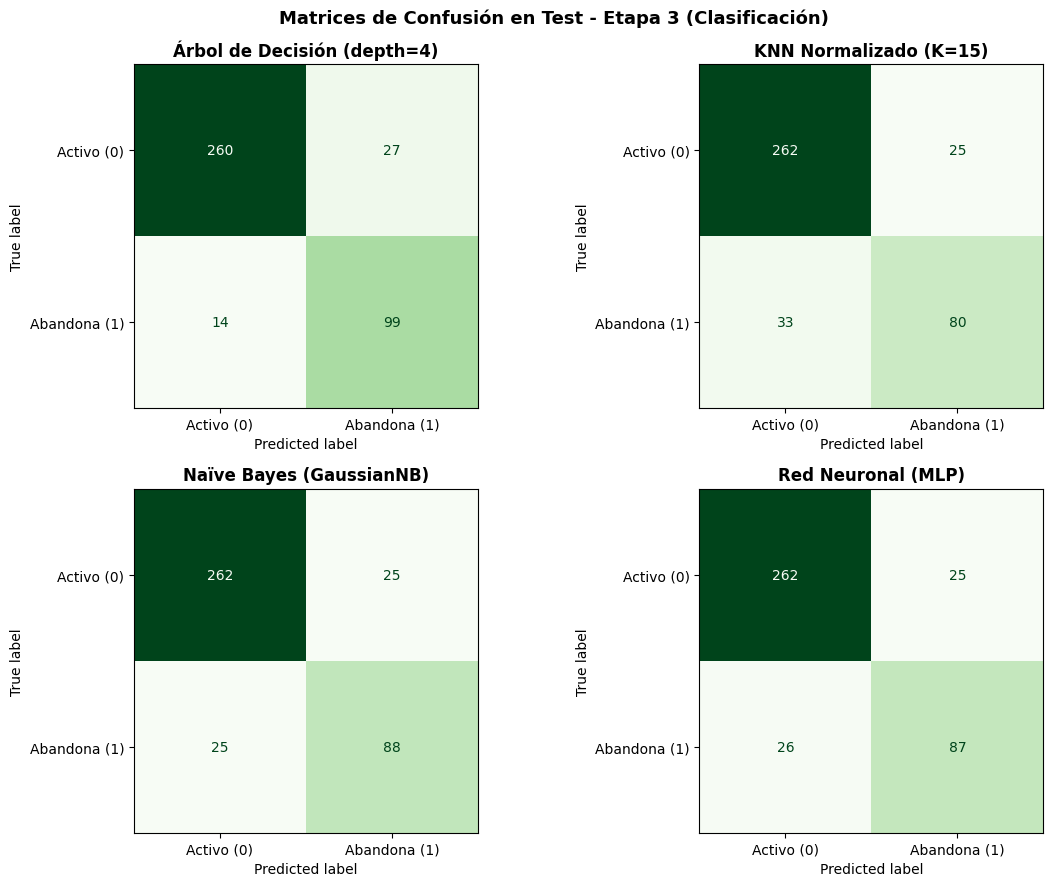

In [13]:
# 1. Construcción de la tabla comparativa sobre el conjunto de prueba (Test)
modelos_eval = [
    ('Modelo Base (Dummy)', y_pred_dummy),
    ('Árbol de Decisión (depth=4)', y_pred_arbol),
    ('Árbol Balanceado (class_weight)', y_pred_arbol_bal),
    (f'KNN Normalizado (K={k_optimo})', y_pred_knn_norm),
    (f'KNN Sin Normalizar (K={k_optimo})', y_pred_knn_sin),
    ('Naïve Bayes (GaussianNB)', y_pred_nb),
    ('Red Neuronal Simple (MLP)', y_pred_mlp)
]

resultados_etapa3 = []
for nombre, y_p in modelos_eval:
    resultados_etapa3.append({
        'Modelo': nombre,
        'Accuracy': round(accuracy_score(y_test, y_p), 4),
        'Precision (Abandona)': round(precision_score(y_test, y_p, zero_division=0), 4),
        'Recall (Abandona)': round(recall_score(y_test, y_p, zero_division=0), 4),
        'F1-Score (Abandona)': round(f1_score(y_test, y_p, zero_division=0), 4)
    })

tabla_clasificacion = pd.DataFrame(resultados_etapa3).sort_values(by='Recall (Abandona)', ascending=False)
print("TABLA COMPARATIVA DE CLASIFICADORES (CONJUNTO DE PRUEBA - TEST):")
display(tabla_clasificacion)

# 2. Matrices de Confusión visuales de los 4 clasificadores principales
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
axes = axes.flatten()

principales = [
    ('Árbol de Decisión (depth=4)', y_pred_arbol),
    (f'KNN Normalizado (K={k_optimo})', y_pred_knn_norm),
    ('Naïve Bayes (GaussianNB)', y_pred_nb),
    ('Red Neuronal (MLP)', y_pred_mlp)
]

for i, (titulo, y_p) in enumerate(principales):
    ConfusionMatrixDisplay.from_predictions(
        y_test, y_p,
        display_labels=['Activo (0)', 'Abandona (1)'],
        cmap='Greens',
        ax=axes[i],
        colorbar=False
    )
    axes[i].set_title(titulo, fontweight='bold')
    axes[i].grid(False)

plt.suptitle('Matrices de Confusión en Test - Etapa 3 (Clasificación)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

**Comparación final de clasificadores y análisis del costo de error:** Al comparar todos los modelos sobre el conjunto de prueba, se confirma que los algoritmos entrenados superan ampliamente al modelo base (`DummyClassifier`, con 0% de *Recall*). En el contexto del gimnasio, **la métrica prioritaria es el *Recall* de la clase `Abandona (1)`**, dado que el costo de un **Falso Negativo** (no detectar a un socio en riesgo y perder su cuota mensual) es muy superior al de un **Falso Positivo** (enviar un mensaje de seguimiento o rutina personalizada a un socio que finalmente no iba a darse de baja). En este escenario, el **Árbol de Decisión (`max_depth=4`)** se posiciona como el mejor modelo al alcanzar un **87,6% de *Recall*** (detectando 99 de los 113 abandonos reales con solo 14 falsos negativos) y un **89,8% de *Accuracy***, seguido por **Naïve Bayes** (77,9% de *Recall*) y la **Red Neuronal MLP** (77,0% de *Recall*).

**ETAPA 4: Regresión y Predicción - ¿Qué nivel de asistencia se espera?**

Regresión Lineal (Pronóstico de Asistencia Mnesual) e Interpretación de Coheficientes

In [14]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Para predecir 'asistencias_mes' sin fuga de información, excluimos 'tasa_cumplimiento' (ya que usa asistencias_mes en su cálculo)
# y la variable objetivo de clasificación 'abandona'
cols_reg = [c for c in X_train.columns if c not in ['asistencias_mes', 'tasa_cumplimiento']]

X_train_reg = X_train[cols_reg]
X_test_reg = X_test[cols_reg]
y_train_reg = X_train['asistencias_mes']
y_test_reg = X_test['asistencias_mes']

# Estandarizamos las features para comparar la magnitud real de los coeficientes en igualdad de escala
scaler_reg = StandardScaler()
X_train_reg_sc = scaler_reg.fit_transform(X_train_reg)
X_test_reg_sc = scaler_reg.transform(X_test_reg)

# Entrenamiento de Regresión Lineal
reg_lineal = LinearRegression()
reg_lineal.fit(X_train_reg_sc, y_train_reg)
y_pred_reg = reg_lineal.predict(X_test_reg_sc)

# Cálculo de métricas exigidas: MAE, RMSE y R2
mae = mean_absolute_error(y_test_reg, y_pred_reg)
rmse = np.sqrt(mean_squared_error(y_test_reg, y_pred_reg))
r2 = r2_score(y_test_reg, y_pred_reg)

print("EVALUACIÓN REGRESIÓN LINEAL (PREDICCIÓN DE ASISTENCIAS MENSUALES):")
print(f"MAE  (Error Absoluto Medio):      {mae:.3f} clases/mes")
print(f"RMSE (Raíz Error Cuadrático):     {rmse:.3f} clases/mes")
print(f"R²   (Coeficiente Determinación): {r2:.3f}")

# Tabla de coeficientes estandarizados ordenados por impacto absoluto
coef_df = pd.DataFrame({
    'Variable': cols_reg,
    'Coeficiente_Estandarizado': reg_lineal.coef_.round(4),
    'Impacto_Absoluto': np.abs(reg_lineal.coef_).round(4)
}).sort_values(by='Impacto_Absoluto', ascending=False)

print("\nCOEFICIENTES MÁS INFLUYENTES (EN ESCALA ESTANDARIZADA):")
display(coef_df.head(8))

EVALUACIÓN REGRESIÓN LINEAL (PREDICCIÓN DE ASISTENCIAS MENSUALES):
MAE  (Error Absoluto Medio):      1.622 clases/mes
RMSE (Raíz Error Cuadrático):     2.015 clases/mes
R²   (Coeficiente Determinación): 0.891

COEFICIENTES MÁS INFLUYENTES (EN ESCALA ESTANDARIZADA):


,Variable,Coeficiente_Estandarizado,Impacto_Absoluto
1,variacion_asistencia,2.2608,2.2608
0,dias_inactividad,-1.6178,1.6178
5,indice_riesgo_conductual,-1.0916,1.0916
2,inasistencias_mes,-1.0773,1.0773
6,caida_critica,-0.3939,0.3939
3,demora_pago_dias,-0.3055,0.3055
11,tipo_disciplina_Yoga,0.0436,0.0436
4,antiguedad_meses,0.0355,0.0355


**Regresión Lineal para pronóstico de asistencia mensual:** Se entrenó un modelo de Regresión Lineal para estimar la cantidad esperada de `asistencias_mes` de cada socio, excluyendo previamente `tasa_cumplimiento` para evitar fuga de información (*data leakage*) al contener la variable objetivo en su fórmula. Las métricas sobre prueba ($\text{MAE} = 1,62\text{ clases/mes}$, $\text{RMSE} = 2,02\text{ clases/mes}$ y $R^2 = 0,891$) muestran un ajuste sólido y cumplen el criterio de error menor a 2 clases mensuales fijado en la Etapa 1. Al analizar los coeficientes estandarizados, se observa que `dias_inactividad`, `indice_riesgo_conductual` e `inasistencias_mes` ejercen el mayor impacto negativo sobre la frecuencia esperada, mientras que una `variacion_asistencia` positiva impulsa al alza las visitas proyectadas.

Regresión Logística para Abandono, Coheficientes y Comparación

In [15]:
from sklearn.linear_model import LogisticRegression

# Entrenamiento de Regresión Logística sobre datos estandarizados
reg_log = LogisticRegression(max_iter=1000, random_state=42)
reg_log.fit(X_train_scaled, y_train)
y_pred_log = reg_log.predict(X_test_scaled)

print("EVALUACIÓN REGRESIÓN LOGÍSTICA (CONJUNTO DE PRUEBA - TEST):")
print(f"Accuracy:  {accuracy_score(y_test, y_pred_log):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_log):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred_log):.4f}")
print(f"F1-Score:  {f1_score(y_test, y_pred_log):.4f}")

# Interpretación de coeficientes (log-odds) ordenados por magnitud absoluta
coef_log_df = pd.DataFrame({
    'Variable': X_train.columns,
    'Coeficiente': reg_log.coef_[0].round(4),
    'Odds_Ratio': np.exp(reg_log.coef_[0]).round(4),
    'Impacto_Absoluto': np.abs(reg_log.coef_[0]).round(4)
}).sort_values(by='Impacto_Absoluto', ascending=False)

print("\nCOEFICIENTES MÁS INFLUYENTES EN REGRESIÓN LOGÍSTICA:")
display(coef_log_df.head(8))

EVALUACIÓN REGRESIÓN LOGÍSTICA (CONJUNTO DE PRUEBA - TEST):
Accuracy:  0.8675
Precision: 0.7727
Recall:    0.7522
F1-Score:  0.7623

COEFICIENTES MÁS INFLUYENTES EN REGRESIÓN LOGÍSTICA:


,Variable,Coeficiente,Odds_Ratio,Impacto_Absoluto
1,asistencias_mes,-1.4290,0.2396,1.4290
6,tasa_cumplimiento,0.7676,2.1546,0.7676
2,variacion_asistencia,-0.4083,0.6648,0.4083
0,dias_inactividad,0.3353,1.3984,0.3353
3,inasistencias_mes,0.3302,1.3912,0.3302
7,indice_riesgo_conductual,0.3278,1.3879,0.3278
4,demora_pago_dias,0.2627,1.3005,0.2627
11,tipo_disciplina_Gimnasio,0.0998,1.1049,0.0998


**Regresión Logística y comparación con clasificadores de Etapa 3:** La Regresión Logística alcanza métricas sólidas en prueba (`Accuracy = 86,8%`, `Precision = 77,3%`, `Recall = 75,2%` y `F1-Score = 76,2%`), ubicándose en un nivel similar a **Naïve Bayes** y la **Red Neuronal MLP** —aunque por debajo del **Árbol de Decisión** en sensibilidad—, aportando una **interpretabilidad paramétrica directa** mediante el signo y magnitud de sus coeficientes. Los valores positivos en `dias_inactividad`, `inasistencias_mes`, `indice_riesgo_conductual` y `demora_pago_dias` incrementan la probabilidad de abandono (con *Odds Ratios* entre `1,30` y `1,40`), mientras que una mayor cantidad de `asistencias_mes` ($\text{OR} = 0,24$) y una `variacion_asistencia` favorable ($\text{OR} = 0,66$) actúan como los principales factores protectores frente a la baja.

Overfitting vs Underfitting y Comparación de Escenarios

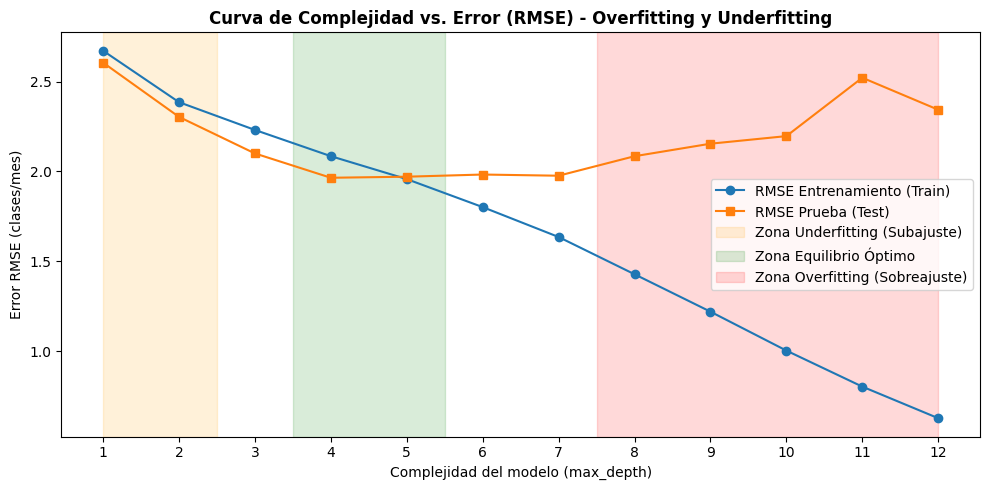

COMPARACIÓN DE ESCENARIOS EN REGRESIÓN (PREDICCIÓN DE ASISTENCIAS):
Escenario A (Solo perfil inicial - sin conducta): MAE=5.26 | RMSE=6.16 | R²=-0.013
Escenario B (Con seguimiento conductual limpio):  MAE=1.62 | RMSE=2.02 | R²=0.891


In [16]:
from sklearn.tree import DecisionTreeRegressor

# 1. Análisis de Overfitting y Underfitting variando la complejidad del modelo (profundidad)
profundidades_reg = range(1, 13)
rmse_train_list, rmse_test_list = [], []

for d in profundidades_reg:
    dtr = DecisionTreeRegressor(max_depth=d, random_state=42)
    dtr.fit(X_train_reg, y_train_reg)
    rmse_train_list.append(np.sqrt(mean_squared_error(y_train_reg, dtr.predict(X_train_reg))))
    rmse_test_list.append(np.sqrt(mean_squared_error(y_test_reg, dtr.predict(X_test_reg))))

plt.figure(figsize=(10, 5))
plt.plot(profundidades_reg, rmse_train_list, marker='o', label='RMSE Entrenamiento (Train)')
plt.plot(profundidades_reg, rmse_test_list, marker='s', label='RMSE Prueba (Test)')

# Señalamos visualmente las zonas de Underfitting, Óptimo y Overfitting
plt.axvspan(1, 2.5, color='orange', alpha=0.15, label='Zona Underfitting (Subajuste)')
plt.axvspan(3.5, 5.5, color='green', alpha=0.15, label='Zona Equilibrio Óptimo')
plt.axvspan(7.5, 12, color='red', alpha=0.15, label='Zona Overfitting (Sobreajuste)')

plt.title('Curva de Complejidad vs. Error (RMSE) - Overfitting y Underfitting', fontweight='bold')
plt.xlabel('Complejidad del modelo (max_depth)')
plt.ylabel('Error RMSE (clases/mes)')
plt.xticks(profundidades_reg)
plt.legend()
plt.tight_layout()
plt.show()

# 2. Comparación de Dos Escenarios para predecir 'asistencias_mes'
# Escenario A: Solo perfil base del socio (alerta temprana al ingreso, sin historial operativo)
cols_escenario_a = ['antiguedad_meses'] + [c for c in X_train.columns if c.startswith('tipo_disciplina_')]
lr_esc_a = LinearRegression().fit(X_train[cols_escenario_a], y_train_reg)
pred_esc_a = lr_esc_a.predict(X_test[cols_escenario_a])

# Escenario B: Con seguimiento conductual del mes (sin incluir variables con fuga como tasa_cumplimiento)
rmse_a = np.sqrt(mean_squared_error(y_test_reg, pred_esc_a))
r2_a = r2_score(y_test_reg, pred_esc_a)

print("COMPARACIÓN DE ESCENARIOS EN REGRESIÓN (PREDICCIÓN DE ASISTENCIAS):")
print(f"Escenario A (Solo perfil inicial - sin conducta): MAE={mean_absolute_error(y_test_reg, pred_esc_a):.2f} | RMSE={rmse_a:.2f} | R²={r2_a:.3f}")
print(f"Escenario B (Con seguimiento conductual limpio):  MAE={mae:.2f} | RMSE={rmse:.2f} | R²={r2:.3f}")

**Análisis de Overfitting/Underfitting y comparación de escenarios:** En la curva de complejidad se distinguen claramente tres regiones: con profundidades bajas (`max_depth` 1 a 2) ambos errores son altos (**Underfitting** por exceso de simplicidad); entre profundidades 4 y 5 se alcanza el **equilibrio óptimo** donde el error en prueba es mínimo ($\text{RMSE} \approx 1,96$); y a partir de profundidad 8 el error en entrenamiento cae hacia cero mientras el error en prueba vuelve a subir (**Overfitting** por memorización del ruido). Por otra parte, al contrastar los dos escenarios de predicción, se demuestra que conocer únicamente el perfil estático inicial (**Escenario A**: $\text{MAE} = 5,26$, $\text{RMSE} = 6,16$ y $R^2 = -0,013$) resulta insuficiente para proyectar la asistencia mensual, mientras que incorporar las métricas conductuales recientes (**Escenario B**: $\text{MAE} = 1,62$, $\text{RMSE} = 2,02$ y $R^2 = 0,891$) mejora drásticamente la capacidad predictiva sin incurrir en fuga de información (*data leakage*), la cual sí ocurriría si se incluyera `tasa_cumplimiento` al derivarse directamente de `asistencias_mes`.

**ETAPA 5: Clustering y Reglas de Asociación - Perfiles y Patrones**

K-Means - Selección de K, Perfiles por centroide y Tasa de Abandono

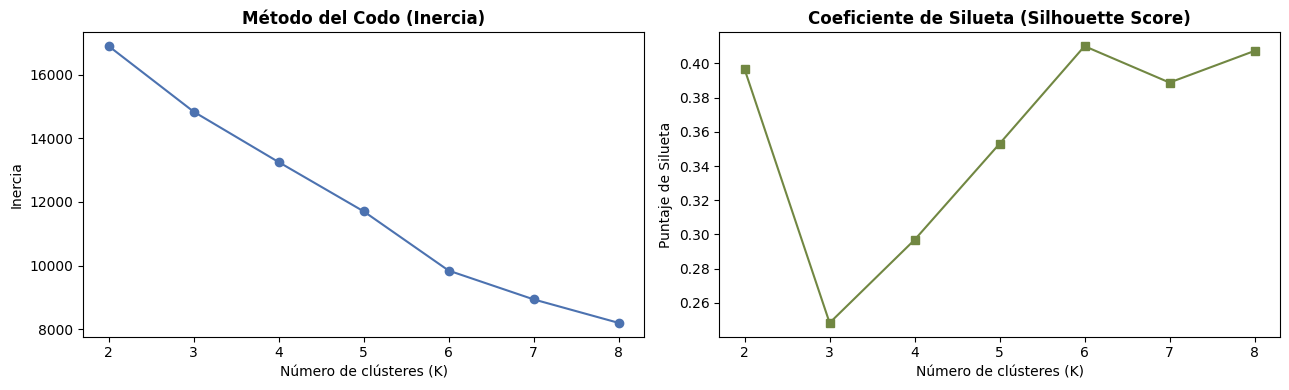

CARACTERIZACIÓN DE CLÚSTERES POR CENTROIDE (UNIDADES REALES) Y RIESGO DE ABANDONO:


,asistencias_mes,dias_inactividad,variacion_asistencia,demora_pago_dias,antiguedad_meses,indice_riesgo_conductual,Tasa_Abandono (%),Cantidad_Socios
Cluster_KMeans,,,,,,,,
0,13.62,8.01,-0.48,5.70,14.88,16.57,8.66,566
1,13.72,8.21,-0.26,5.63,14.63,16.65,6.39,829
2,1.27,42.93,-10.47,25.75,14.78,81.55,76.69,605


In [17]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Usamos el conjunto completo limpio e imputado para descubrir perfiles globales de socios
# (excluyendo la etiqueta 'abandona' para que el agrupamiento sea estrictamente no supervisado)
X_clust_raw = pd.concat([X_train, X_test], axis=0).sort_index()
y_clust_ref = pd.concat([y_train, y_test], axis=0).sort_index()

# Estandarizamos obligatoriamente porque K-Means usa distancia euclidiana
scaler_clust = StandardScaler()
X_clust_scaled = scaler_clust.fit_transform(X_clust_raw)

# 1. Método del Codo y Coeficiente de Silueta para K de 2 a 8
k_rango = range(2, 9)
inercias, siluetas = [], []

for k in k_rango:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    etiquetas = km.fit_predict(X_clust_scaled)
    inercias.append(km.inertia_)
    siluetas.append(silhouette_score(X_clust_scaled, etiquetas))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(k_rango, inercias, marker='o', color='#4C72B0')
axes[0].set_title('Método del Codo (Inercia)', fontweight='bold')
axes[0].set_xlabel('Número de clústeres (K)')
axes[0].set_ylabel('Inercia')

axes[1].plot(k_rango, siluetas, marker='s', color='#718742')
axes[1].set_title('Coeficiente de Silueta (Silhouette Score)', fontweight='bold')
axes[1].set_xlabel('Número de clústeres (K)')
axes[1].set_ylabel('Puntaje de Silueta')

plt.tight_layout()
plt.show()

# 2. Entrenamiento de K-Means con K=3 (perfiles comerciales claramente diferenciados)
k_elegido = 3
kmeans_final = KMeans(n_clusters=k_elegido, random_state=42, n_init=10)
clusters_km = kmeans_final.fit_predict(X_clust_scaled)

# 3. Análisis de centroides en unidades reales + cruce con tasa de abandono
df_perfiles = X_clust_raw[['asistencias_mes', 'dias_inactividad', 'variacion_asistencia', 'demora_pago_dias', 'antiguedad_meses', 'indice_riesgo_conductual']].copy()
df_perfiles['Cluster_KMeans'] = clusters_km
df_perfiles['Tasa_Abandono (%)'] = y_clust_ref * 100

resumen_clusters = df_perfiles.groupby('Cluster_KMeans').mean().round(2)
resumen_clusters['Cantidad_Socios'] = df_perfiles.groupby('Cluster_KMeans').size()

print("CARACTERIZACIÓN DE CLÚSTERES POR CENTROIDE (UNIDADES REALES) Y RIESGO DE ABANDONO:")
display(resumen_clusters)

**Segmentación con K-Means y cruce con riesgo de abandono:** Combinando el punto de inflexión en el **Método del Codo** y el **Coeficiente de Silueta (`0,2482`)**, se seleccionaron **3 clústeres operativos ($K = 3$)** sin utilizar la etiqueta `abandona` durante el agrupamiento. Al inspeccionar los centroides en unidades reales, emergen tres perfiles bien diferenciados:

* **Clúster 0 — Socios Activos Segmento A (566 socios):** Promedian `13,62` clases/mes, baja inactividad (`8,01` días), pagos al día (`5,70` días de demora), bajo riesgo conductual (`16,57`) y una tasa de abandono de solo **8,66%**.
* **Clúster 1 — Socios Activos Segmento B (829 socios):** Presentan un comportamiento prácticamente idéntico (`13,72` clases/mes, `8,21` días de inactividad y `5,63` días de demora), diferenciándose por su distribución de disciplinas y registrando una tasa de abandono de apenas **6,39%**.
* **Clúster 2 — Socios Críticos / En Abandono (605 socios):** Registran muy baja asistencia (`1,27` clases/mes), fuerte caída mensual (`-10,47` clases), `42,93` días sin asistir, atrasos marcados en la cuota (`25,75` días) y un índice de riesgo conductual de `81,55`, concentrando una tasa de deserción del **76,69%** (equivalente a más del **81%** de las bajas totales del centro deportivo).

Clustering Jerárquico y Comparación de K-Means

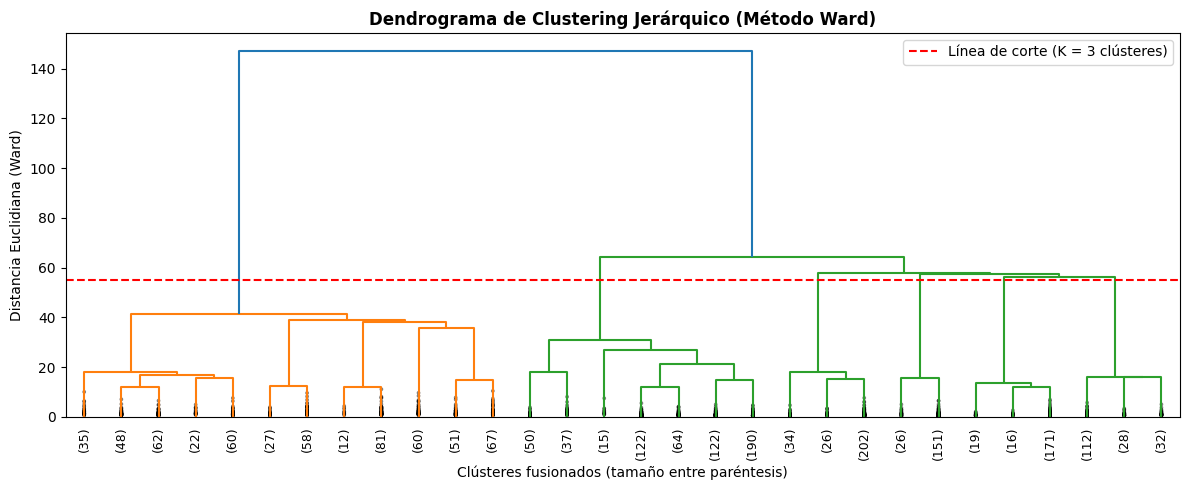

COMPARACIÓN DE CALIDAD DE AGRUPAMIENTO (SILHOUETTE SCORE):
- K-Means (K=3):               0.2482
- Clustering Jerárquico (K=3): 0.2457

TABLA DE CONTINGENCIA (K-MEANS VS. JERÁRQUICO):


Jerárquico,0,1,2
K-Means,,,
0,0,1,565
1,813,7,9
2,4,575,26


In [18]:
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.cluster import AgglomerativeClustering

# 1. Cálculo de la matriz de enlace con método 'ward' (minimiza la varianza intra-clúster)
Z = linkage(X_clust_scaled, method='ward')

# Visualización del dendrograma (truncado a los últimos 30 nodos fusionados para legibilidad)
plt.figure(figsize=(12, 5))
dendrogram(
    Z,
    truncate_mode='lastp',
    p=30,
    leaf_rotation=90,
    leaf_font_size=9,
    show_contracted=True
)
plt.axhline(y=55, color='red', linestyle='--', label='Línea de corte (K = 3 clústeres)')
plt.title('Dendrograma de Clustering Jerárquico (Método Ward)', fontweight='bold')
plt.xlabel('Clústeres fusionados (tamaño entre paréntesis)')
plt.ylabel('Distancia Euclidiana (Ward)')
plt.legend()
plt.tight_layout()
plt.show()

# 2. Entrenamiento de AgglomerativeClustering con K=3 y comparación con K-Means
jerarquico = AgglomerativeClustering(n_clusters=3, linkage='ward')
clusters_jer = jerarquico.fit_predict(X_clust_scaled)

sil_km = silhouette_score(X_clust_scaled, clusters_km)
sil_jer = silhouette_score(X_clust_scaled, clusters_jer)

print("COMPARACIÓN DE CALIDAD DE AGRUPAMIENTO (SILHOUETTE SCORE):")
print(f"- K-Means (K=3):               {sil_km:.4f}")
print(f"- Clustering Jerárquico (K=3): {sil_jer:.4f}")

print("\nTABLA DE CONTINGENCIA (K-MEANS VS. JERÁRQUICO):")
display(pd.crosstab(clusters_km, clusters_jer, rownames=['K-Means'], colnames=['Jerárquico']))

**Clustering Jerárquico y comparación con K-Means:** Al construir el dendrograma mediante el criterio de enlace **Ward**, se observa un salto vertical pronunciado en la distancia de fusión que respalda visualmente el corte en **3 grandes segmentos**, validando la elección previa de $K = 3$. Al comparar ambos algoritmos mediante el *Silhouette Score* (`0,2482` en K-Means frente a `0,2457` en Jerárquico) y la tabla de contingencia cruzada (**97,65% de coincidencia** en la asignación de los 2.000 socios), se comprueba una alta coherencia estructural en la separación entre socios activos y socios críticos en riesgo, destacando el clustering jerárquico por su trazabilidad visual y K-Means por su mayor cohesión interna y eficiencia computacional.

Reglas de Asociación con Aprori (Top 10 por Lift hacia el Abandono)

In [19]:
import warnings
warnings.filterwarnings('ignore')

from mlxtend.frequent_patterns import apriori, association_rules

# 1. Transformamos la tabla discretizada en matriz binaria (One-Hot) para Apriori
df_binario = pd.get_dummies(df_transacciones, dtype=bool)

# 2. Extracción de conjuntos de ítems frecuentes
# Fijamos min_support=0.05 (5% de los socios = al menos 100 casos) para evitar reglas anecdóticas
itemsets_frecuentes = apriori(df_binario, min_support=0.05, use_colnames=True)

# 3. Generación de reglas con confianza mínima del 60% (min_threshold=0.60)
reglas = association_rules(itemsets_frecuentes, metric="confidence", min_threshold=0.60)

# 4. Filtramos exclusivamente las reglas cuyo consecuente sea exactamente 'Estado_Cliente_Abandona'
reglas_abandono = reglas[
    reglas['consequents'].apply(lambda x: x == frozenset({'Estado_Cliente_Abandona'}))
].copy()

# Ordenamos por Lift descendente y seleccionamos las 10 principales
top10_reglas = reglas_abandono.sort_values(by='lift', ascending=False).head(10).copy()

# Formateamos antecedentes y consecuentes como texto legible
top10_reglas['Antecedentes (SI ocurre...)'] = top10_reglas['antecedents'].apply(lambda x: ', '.join(sorted(list(x))))
top10_reglas['Consecuente (ENTONCES...)'] = 'Estado_Cliente_Abandona'

columnas_mostrar = [
    'Antecedentes (SI ocurre...)', 'Consecuente (ENTONCES...)',
    'support', 'confidence', 'lift'
]

print(f"Total de reglas de abandono encontradas: {len(reglas_abandono)}")
print("TOP 10 REGLAS DE ASOCIACIÓN CON MAYOR LIFT HACIA EL ABANDONO:")
display(top10_reglas[columnas_mostrar].round(4))

Total de reglas de abandono encontradas: 28
TOP 10 REGLAS DE ASOCIACIÓN CON MAYOR LIFT HACIA EL ABANDONO:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Antecedentes (SI ocurre...),Consecuente (ENTONCES...),support,confidence,lift
356,"Nivel_Asistencia_Asistencia_Baja, Nivel_Demora...",Estado_Cliente_Abandona,0.0755,0.7865,2.7790
409,"Antiguedad_Cat_Socio_Regular, Nivel_Asistencia...",Estado_Cliente_Abandona,0.0620,0.7848,2.7732
147,"Nivel_Asistencia_Asistencia_Baja, tipo_discipl...",Estado_Cliente_Abandona,0.0925,0.7839,2.7700
350,"Antiguedad_Cat_Socio_Antiguo, Nivel_Asistencia...",Estado_Cliente_Abandona,0.0790,0.7822,2.7639
200,"Nivel_Demora_Pago_Demora_Critica, tipo_discipl...",Estado_Cliente_Abandona,0.0825,0.7820,2.7632
137,"Nivel_Asistencia_Asistencia_Baja, Nivel_Demora...",Estado_Cliente_Abandona,0.1775,0.7819,2.7630
322,"Nivel_Asistencia_Asistencia_Baja, Nivel_Inacti...",Estado_Cliente_Abandona,0.0815,0.7799,2.7558
328,"Antiguedad_Cat_Socio_Regular, Nivel_Demora_Pag...",Estado_Cliente_Abandona,0.0655,0.7798,2.7553
297,"Nivel_Asistencia_Asistencia_Baja, Nivel_Demora...",Estado_Cliente_Abandona,0.1575,0.7797,2.7551
145,"Antiguedad_Cat_Socio_Antiguo, Nivel_Asistencia...",Estado_Cliente_Abandona,0.0965,0.7782,2.7499


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

**Extracción e interpretación de reglas de asociación con Apriori:** Se establecieron umbrales de **soporte mínimo del 5%** (garantizando al menos 100 socios por patrón para evitar ruido estadístico) y **confianza mínima del 60%**, obteniendo **28 reglas de abandono** ordenadas por *Lift* para identificar las combinaciones que multiplican la probabilidad base de baja (`28,3%`). Los patrones más fuertes muestran que la combinación simultánea de **baja asistencia mensual (`Asistencia_Baja`)**, **inactividad alta (`Inactividad_Alta`)** y **demora crítica en el pago (`Demora_Critica`)** eleva el *Lift* hasta **2,78** (con una confianza cercana al **78,7%**, casi triplicando la tasa esperada de baja), independientemente de la disciplina practicada. Asimismo, se descartan reglas redundantes que solo repiten subconjuntos de estas mismas condiciones y se recuerda que la asociación estadística indica co-ocurrencia conductual y no causalidad directa.

**ETAPA 6: Evaluación, Validadción y Recomendación Final**

Validación Cruzada Estratificada de 10 Pliegues (media y desvío estándar)

In [20]:
import warnings
warnings.filterwarnings('ignore')

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [21]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import make_pipeline

# Definimos la validación cruzada estratificada de 10 pliegues con semilla fija
skf = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

# Evaluamos todos los clasificadores (encapsulando StandardScaler dentro de make_pipeline para evitar fuga en cada pliegue)
modelos_cv = {
    'Árbol de Decisión (depth=4)': DecisionTreeClassifier(criterion='gini', max_depth=4, min_samples_split=10, min_samples_leaf=5, random_state=42),
    f'KNN Normalizado (K={k_optimo})': make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k_optimo)),
    'Naïve Bayes (GaussianNB)': make_pipeline(StandardScaler(), GaussianNB()),
    'Red Neuronal (MLP)': make_pipeline(StandardScaler(), MLPClassifier(hidden_layer_sizes=(32, 16), max_iter=500, early_stopping=True, random_state=42)),
    'Regresión Logística': make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=42))
}

metricas_cv = ['accuracy', 'precision', 'recall', 'f1']
resumen_cv = []

# Evaluamos sobre todo el conjunto de entrenamiento (1.600 socios) para mantener Test intacto como auditoría final
for nombre, modelo in modelos_cv.items():
    scores = cross_validate(modelo, X_train, y_train, cv=skf, scoring=metricas_cv)
    resumen_cv.append({
        'Modelo': nombre,
        'Accuracy (Media ± DE)': f"{scores['test_accuracy'].mean():.4f} ± {scores['test_accuracy'].std():.4f}",
        'Precision (Media ± DE)': f"{scores['test_precision'].mean():.4f} ± {scores['test_precision'].std():.4f}",
        'Recall (Media ± DE)': f"{scores['test_recall'].mean():.4f} ± {scores['test_recall'].std():.4f}",
        'F1-Score (Media ± DE)': f"{scores['test_f1'].mean():.4f} ± {scores['test_f1'].std():.4f}",
        'Recall_Num': scores['test_recall'].mean()
    })

tabla_cv = pd.DataFrame(resumen_cv).sort_values(by='Recall_Num', ascending=False).drop(columns=['Recall_Num'])
print("VALIDACIÓN CRUZADA ESTRATIFICADA DE 10 PLIEGUES (MEDIA ± DESVÍO ESTÁNDAR):")
display(tabla_cv)

VALIDACIÓN CRUZADA ESTRATIFICADA DE 10 PLIEGUES (MEDIA ± DESVÍO ESTÁNDAR):


,Modelo,Accuracy (Media ± DE),Precision (Media ± DE),Recall (Media ± DE),F1-Score (Media ± DE)
0,Árbol de Decisión (depth=4),0.8856 ± 0.0227,0.7666 ± 0.0504,0.8655 ± 0.0649,0.8107 ± 0.0373
2,Naïve Bayes (GaussianNB),0.8787 ± 0.0247,0.7620 ± 0.0522,0.8390 ± 0.0604,0.7967 ± 0.0404
3,Red Neuronal (MLP),0.8744 ± 0.0241,0.7566 ± 0.0557,0.8300 ± 0.0548,0.7895 ± 0.0371
4,Regresión Logística,0.8769 ± 0.0278,0.7651 ± 0.0530,0.8214 ± 0.0747,0.7901 ± 0.0488
1,KNN Normalizado (K=15),0.8738 ± 0.0259,0.7679 ± 0.0563,0.8015 ± 0.0609,0.7824 ± 0.0439


**Validación cruzada estratificada (10 pliegues):** Al evaluar todos los clasificadores mediante 10 pliegues estratificados (encapsulando el escalado dentro de cada pliegue para evitar fuga de información), se confirma la estabilidad general del sistema. El **Árbol de Decisión (`max_depth=4`)** lidera tanto la sensibilidad como el desempeño global con un **86,6% de *Recall*** ($\pm 6,5\%$), **88,6% de *Accuracy*** y **76,7% de *Precision***, seguido por **Naïve Bayes (`83,9%` de *Recall*)**, la **Red Neuronal MLP (`83,0%`)**, la **Regresión Logística (`82,1%`)** y **KNN Normalizado (`80,2%`)**. Todos los algoritmos superan el umbral del **80% de *Recall* promedio** fijado en la Etapa 1 con desvíos estándar acotados.

Matriz de confusión en cantidad de socios y el control de equidad por disciplina

In [22]:
from sklearn.metrics import confusion_matrix, recall_score, precision_score, accuracy_score

# Predicciones finales del modelo seleccionado (Árbol de Decisión max_depth=4) sobre Test
y_pred_final = arbol.predict(X_test)
tn, fp, fn, tp = confusion_matrix(y_test, y_pred_final).ravel()

print("1. IMPACTO EN PERSONAS — MATRIZ DE CONFUSIÓN (CONJUNTO DE PRUEBA: 400 SOCIOS)")
print(f"- Verdaderos Negativos (VN): {tn} socios activos correctamente identificados (sin alertas innecesarias)")
print(f"- Falsos Positivos (FP):     {fp} socios activos marcados por error con alerta preventiva")
print(f"- Verdaderos Positivos (VP): {tp} bajas reales detectadas a tiempo ({tp/(tp+fn)*100:.1f}% de Recall)")
print(f"- Falsos Negativos (FN):     {fn} bajas reales no detectadas por el modelo")

# 2. Auditoría de Equidad Algorítmica por Disciplina
cols_disc = [c for c in X_test.columns if c.startswith('tipo_disciplina_')]
disciplina_test = X_test[cols_disc].idxmax(axis=1).str.replace('tipo_disciplina_', '')

tabla_equidad = []
for disc in sorted(disciplina_test.unique()):
    mask = (disciplina_test == disc)
    yt_d = y_test[mask]
    yp_d = y_pred_final[mask]
    tabla_equidad.append({
        'Disciplina': disc,
        'Socios_Test': len(yt_d),
        'Bajas_Reales': int(yt_d.sum()),
        'Detectados_VP': int(((yt_d == 1) & (yp_d == 1)).sum()),
        'Recall (%)': round(recall_score(yt_d, yp_d, zero_division=0) * 100, 1),
        'Precision (%)': round(precision_score(yt_d, yp_d, zero_division=0) * 100, 1),
        'Accuracy (%)': round(accuracy_score(yt_d, yp_d) * 100, 1)
    })

df_equidad = pd.DataFrame(tabla_equidad)
print("\n2. AUDITORÍA DE EQUIDAD POR DISCIPLINA (CONTROL DE SESGO):")
display(df_equidad)

1. IMPACTO EN PERSONAS — MATRIZ DE CONFUSIÓN (CONJUNTO DE PRUEBA: 400 SOCIOS)
- Verdaderos Negativos (VN): 260 socios activos correctamente identificados (sin alertas innecesarias)
- Falsos Positivos (FP):     27 socios activos marcados por error con alerta preventiva
- Verdaderos Positivos (VP): 99 bajas reales detectadas a tiempo (87.6% de Recall)
- Falsos Negativos (FN):     14 bajas reales no detectadas por el modelo

2. AUDITORÍA DE EQUIDAD POR DISCIPLINA (CONTROL DE SESGO):


,Disciplina,Socios_Test,Bajas_Reales,Detectados_VP,Recall (%),Precision (%),Accuracy (%)
0,Boxeo,52,17,16,94.1,80.0,90.4
1,Danza,46,10,9,90.0,81.8,93.5
2,Gimnasio,160,52,46,88.5,76.7,87.5
3,Pilates,69,15,13,86.7,76.5,91.3
4,Yoga,73,19,15,78.9,83.3,90.4


**Impacto operativo y auditoría de equidad por disciplina:** Al traducir la matriz de confusión del **Árbol de Decisión (`max_depth=4`)** sobre los **400 socios de prueba** a decisiones de gestión, el modelo detecta oportunamente **99 de las 113 bajas reales** (*Verdaderos Positivos*, `87,6%` de *Recall*), dejando escapar solo **14 casos** (*Falsos Negativos*) y generando **27 alertas preventivas** sobre socios activos (*Falsos Positivos*), cuyo costo operativo es mínimo (un mensaje de seguimiento). Asimismo, al auditar el rendimiento desagregado por `tipo_disciplina`, se verifica una cobertura equilibrada en todas las actividades —destacando **Boxeo (`94,1%` de *Recall*)**, **Danza (`90,0%`)**, **Gimnasio (`88,5%`)** y **Pilates (`86,7%`)**, con un leve descenso en **Yoga (`78,9%`)**—, descartando sesgos discriminatorios graves hacia segmentos específicos del centro deportivo.

Archivo CSV limpio

In [23]:
# Exportar dataset limpio con predicciones reales del Árbol de Decisión para Lovable
df_tablero = pd.read_csv('clientes_fitness.csv').drop_duplicates().copy()

# Aplicar las mismas reglas de limpieza de Etapa 2
df_tablero.loc[df_tablero['asistencias_mes'] > 31, 'asistencias_mes'] = np.nan
df_tablero.loc[df_tablero['demora_pago_dias'] < 0, 'demora_pago_dias'] = np.nan
df_tablero['dias_inactividad'] = df_tablero['dias_inactividad'].clip(upper=90)
df_tablero['antiguedad_meses'] = df_tablero['antiguedad_meses'].clip(upper=120)

for col in ['dias_inactividad', 'asistencias_mes', 'variacion_asistencia', 'inasistencias_mes', 'demora_pago_dias', 'antiguedad_meses']:
    df_tablero[col] = df_tablero[col].fillna(df_tablero[col].median())
df_tablero['tipo_disciplina'] = df_tablero['tipo_disciplina'].fillna(df_tablero['tipo_disciplina'].mode()[0])

# Variables derivadas
df_tablero['tasa_cumplimiento'] = (df_tablero['asistencias_mes'] / (df_tablero['asistencias_mes'] + df_tablero['inasistencias_mes']).replace(0, 1)).round(2)
df_tablero['indice_riesgo_conductual'] = (df_tablero['dias_inactividad'] * 0.6 + df_tablero['demora_pago_dias'] * 0.4).round(1)
df_tablero['caida_critica'] = (df_tablero['variacion_asistencia'] <= -5).astype(int)

# Generar predicción y probabilidad usando el modelo ya entrenado (arbol)
X_para_pred = pd.get_dummies(df_tablero.drop(columns=['id_alumno', 'nombre_alumno', 'abandona']), columns=['tipo_disciplina'])
X_para_pred = X_para_pred.reindex(columns=arbol.feature_names_in_, fill_value=0)

df_tablero['riesgo_abandono_pct'] = (arbol.predict_proba(X_para_pred)[:, 1] * 100).round(1)
df_tablero['alerta_sistema'] = np.where(arbol.predict(X_para_pred) == 1, 'En Riesgo', 'Activo')

df_tablero.to_csv('tablero_fidelizacion.csv', index=False)
print("Archivo 'tablero_fidelizacion.csv' generado con éxito:", df_tablero.shape)
display(df_tablero[['id_alumno', 'nombre_alumno', 'tipo_disciplina', 'asistencias_mes', 'dias_inactividad', 'demora_pago_dias', 'riesgo_abandono_pct', 'alerta_sistema']].head())

Archivo 'tablero_fidelizacion.csv' generado con éxito: (2000, 15)


,id_alumno,nombre_alumno,tipo_disciplina,asistencias_mes,dias_inactividad,demora_pago_dias,riesgo_abandono_pct,alerta_sistema
0,1001,Emilia Díaz,Pilates,0.0,54.0,20.0,66.1,En Riesgo
1,1002,Antonella Herrera,Gimnasio,12.0,11.0,2.0,4.9,Activo
2,1003,Julián Pereyra,Pilates,11.0,15.0,9.0,4.9,Activo
3,1004,Rocío Núñez,Danza,6.0,26.0,22.0,100.0,En Riesgo
4,1005,Florencia Ortiz,Gimnasio,0.0,60.0,14.0,66.1,En Riesgo
